# Simulation of Inhomogeneous Fokker-Planck-Landau (FPL) Equation
### Fast Spectral Collision Operator Coupled with Conservative Semi-Lagrangian Transport

---
### 1. Overview and Problem Description
The Fokker-Planck-Landau (FPL) equation is the fundamental kinetic equation in plasma physics, describing Coulombian and grazing collision processes in charged particle systems:

$$\frac{\partial f}{\partial t} + v \cdot \nabla_x f = \frac{1}{\varepsilon} Q_L(f, f)$$

where the Landau collision operator is defined in divergence form:
$$Q_L(f, f)(v) = \nabla_v \cdot \int_{\mathbb{R}^d} A(v - v_*) \left[ f(v_*) \nabla_v f(v) - f(v) \nabla_{v_*} f(v_*) \right] dv_*$$

The matrix $A(z)$ is given by:
$$A(z) = \Phi(|z|) \left( I - \frac{z \otimes z}{|z|^2} \right), \quad \Phi(|z|) = C_0 |z|^{\gamma + 2}$$
where $\gamma = 0$ corresponds to Maxwellian molecules ($C_0 = \frac{1}{2\pi}$ in 2D and $\frac{1}{4\pi}$ in 3D), and $\gamma = -3$ corresponds to Coulomb interactions.

In this tutorial, we demonstrate:
1. **Conservative Semi-Lagrangian Transport**: Characteristics-based transport with 5th-order CWENO reconstruction.
2. **Fast Spectral Landau Solver**: Evaluation of the FPL collision operator via Pareschi, Russo, and Toscani (2000).
3. **Diffusion CFL Stability**: Addressing the parabolic diffusion nature ($\Delta t = O(\Delta v^2)$) under explicit Runge-Kutta time stepping.
4. **Conservation of Moments**: Maintaining mass, momentum, and energy conservation.
5. **3D Collision Operator Demonstration**: Validating the 3D collision operator formulation.

#### References:
* [1] L. Pareschi, G. Russo, and G. Toscani, *Fast Spectral Methods for the Fokker–Planck–Landau Collision Operator*, **Journal of Computational Physics**, 165 (2000), pp. 216–236.
* [2] S. Boscarino, B. Cho, and G. Russo, *A Conservative Semi-Lagrangian Method for Inhomogeneous Boltzmann Equation*, **Journal of Computational Physics**, 498 (2024), 112678.



In [1]:
%matplotlib inline
import numpy as np
import torch
import matplotlib.pyplot as plt

from deep_numerical.numerical.solver.fsm__fpl import FastSM_Landau_VHS
from deep_numerical.utils import velocity_grid, space_grid

# Configure plot style and default precision
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120
torch.set_default_dtype(torch.float64)
print(f"PyTorch version: {torch.__version__}, default dtype: {torch.get_default_dtype()}")



PyTorch version: 2.14.1+cpu, default dtype: torch.float64


C:\Users\GJ2\deep_numerical\deep_numerical\utils\__init__.py:8: UserWarning: Module 'torch_geometric' is not installed. 'RandomGraphGenerator' and 'RandomGridGenerator' will not be available.
  from deep_numerical.utils._random_grid   import *


### 2. Benchmark Setup: Smooth Non-Equilibrium Problem
To enable direct comparison with the Inhomogeneous Boltzmann simulation, we adopt the identical physical domain and initial non-equilibrium Maxwellian perturbation:
* Spatial Domain: $x \in [-L_x, L_x]$ with $L_x = 1.0$, periodic boundary condition.
* Velocity Domain: $v = (v_x, v_y) \in [-V_{\max}, V_{\max}]^2$ with $V_{\max} = 6.0$.
* Initial condition:
  $$\rho_0(x) = 1.0 + 0.4 \sin(\pi x)$$
  $$u_{x, 0}(x) = 0.5 (1 - \cos(\pi x)), \quad u_{y, 0}(x) = 0.0$$
  $$T_0(x) = 1.0 + 0.5 \cos(\pi x)$$
  $$f_0(x, v) = \frac{\rho_0(x)}{2\pi T_0(x)} \exp\left( -\frac{|v - u_0(x)|^2}{2 T_0(x)} \right)$$


In [2]:
# Physical & Discretization Parameters
dim_v = 2
N_x   = 64           # Spatial grid resolution
N_v   = 16           # Velocity grid resolution per dimension
x_max = 1.0          # Spatial half-domain [-1, 1]
v_max = 6.0          # Velocity truncation limit [-6, 6]

t_init  = 0.0
t_final = 3.00       # Physical simulation time
delta_t = 1e-3       # Time step respecting diffusion CFL constraint

knudsen = 1.0        # Knudsen number
vhs_coeff = 1.0 / (2.0 * np.pi)  # Pareschi et al. 2000 normalization for 2D Maxwell molecules
vhs_alpha = 0.0      # gamma = 0

print(f"Spatial grid: {N_x} points, dx = {2 * x_max / (N_x - 1):.4f}")
print(f"Velocity grid: {N_v}x{N_v} points, dv = {2 * v_max / N_v:.4f}")
print(f"Time step delta_t = {delta_t:.4f}")



Spatial grid: 64 points, dx = 0.0317
Velocity grid: 16x16 points, dv = 0.7500
Time step delta_t = 0.0010


In [3]:
# Initialize Fast Spectral FPL Solver
solver = FastSM_Landau_VHS(
    dimension           = dim_v,
    v_num_grid          = N_v,
    v_max               = v_max,
    x_num_grid          = N_x,
    x_max               = x_max,
    vhs_coeff           = vhs_coeff,
    vhs_alpha           = vhs_alpha,
    quad_order_uniform  = 16,
    quad_order_legendre = 16,
)

# Configure semi-Lagrangian transport parameters
solver.knudsen                = knudsen
solver.sl_scheme              = 'rk4'       # 4th-order Runge-Kutta time marching
solver.spatial_reconstruction = 'cweno35'   # 5th-order Central WENO reconstruction
solver.moment_correction      = True        # Enforce exact conservation of mass, momentum, energy

print("FPL Solver successfully configured:")
print(f"  - Knudsen number: {solver.knudsen}")
print(f"  - Semi-Lagrangian scheme: {solver.sl_scheme}")
print(f"  - Spatial reconstruction: {solver.spatial_reconstruction}")
print(f"  - Moment correction: {solver.moment_correction}")



FPL Solver successfully configured:
  - Knudsen number: 1.0
  - Semi-Lagrangian scheme: rk4
  - Spatial reconstruction: cweno35
  - Moment correction: True


In [4]:
# Generate 1D spatial coordinates and 2D velocity grid
x_coords = torch.linspace(-x_max, x_max, N_x)     # (N_x,)
v_grid   = velocity_grid(dim_v, N_v, v_max)       # (N_v, N_v, 2)
v_x      = v_grid[..., 0]                         # (N_v, N_v)
v_y      = v_grid[..., 1]                         # (N_v, N_v)

# Macroscopic fields at t = 0
rho_0 = 1.0 + 0.4 * torch.sin(torch.pi * x_coords)
u_x_0 = 0.5 * (1.0 - torch.cos(torch.pi * x_coords))
u_y_0 = torch.zeros_like(u_x_0)
T_0   = 1.0 + 0.5 * torch.cos(torch.pi * x_coords)

# Reshape tensors to match library layout: (batch, space_x, space_y, vel_x, vel_y, value)
x_shape = (1, N_x, 1, 1, 1, 1)
v_shape = (1, 1, 1, N_v, N_v, 1)

rho_b = rho_0.view(*x_shape)
ux_b  = u_x_0.view(*x_shape)
uy_b  = u_y_0.view(*x_shape)
T_b   = T_0.view(*x_shape)

vx_b  = v_x.view(*v_shape)
vy_b  = v_y.view(*v_shape)

# Construct initial perturbed local Maxwellian
c_sq   = (vx_b - ux_b)**2 + (vy_b - uy_b)**2
f_init = (rho_b / (2.0 * torch.pi * T_b)) * torch.exp(-0.5 * c_sq / T_b)

print(f"Initial distribution function tensor shape: {f_init.shape}")



Initial distribution function tensor shape: torch.Size([1, 64, 1, 16, 16, 1])


### 3. Numerical Simulation: Solving the Inhomogeneous FPL Equation
We call `solver.solve()` to advance the system from $t=0$ to $t=3.0$ with time step $\Delta t = 0.001$.


In [5]:
# Run FPL solver
trajectory = solver.solve(
    t_init  = t_init,
    t_final = t_final,
    delta_t = delta_t,
    f_init  = f_init,
)

num_times = trajectory.shape[1]
time_array = np.linspace(t_init, t_final, num_times)
print(f"FPL Simulation completed! Trajectory tensor shape: {trajectory.shape}")
print(f"Number of saved time frames: {num_times}")



  0%|          | 0/3000 [00:00<?, ?it/s]

FPL Simulation completed! Trajectory tensor shape: torch.Size([1, 3001, 64, 1, 16, 16, 1])
Number of saved time frames: 3001


In [6]:
# Compute macroscopic fluid moments across space and time
dv = 2.0 * v_max / N_v
dx = 2.0 * x_max / (N_x - 1)

f_traj = trajectory[0, :, :, 0, :, :, 0]  # shape: (num_times, N_x, N_v, N_v)

# Density: rho(t, x) = \int f dv
rho_traj = torch.sum(f_traj, dim=(-2, -1)) * (dv**2)

# Mean velocity: u_x(t, x) = (1/rho) \int v_x f dv
mom_x_traj = torch.sum(f_traj * v_x.view(1, 1, N_v, N_v), dim=(-2, -1)) * (dv**2)
u_x_traj   = mom_x_traj / rho_traj

# Mean velocity: u_y(t, x) = (1/rho) \int v_y f dv
mom_y_traj = torch.sum(f_traj * v_y.view(1, 1, N_v, N_v), dim=(-2, -1)) * (dv**2)
u_y_traj   = mom_y_traj / rho_traj

# Temperature: T(t, x) = (1 / 2 rho) \int |v - u|^2 f dv
c_x = v_x.view(1, 1, N_v, N_v) - u_x_traj.unsqueeze(-1).unsqueeze(-1)
c_y = v_y.view(1, 1, N_v, N_v) - u_y_traj.unsqueeze(-1).unsqueeze(-1)
c_sq_traj = c_x**2 + c_y**2
T_traj = 0.5 * torch.sum(f_traj * c_sq_traj, dim=(-2, -1)) * (dv**2) / rho_traj

print("Macroscopic moments computed successfully.")



Macroscopic moments computed successfully.


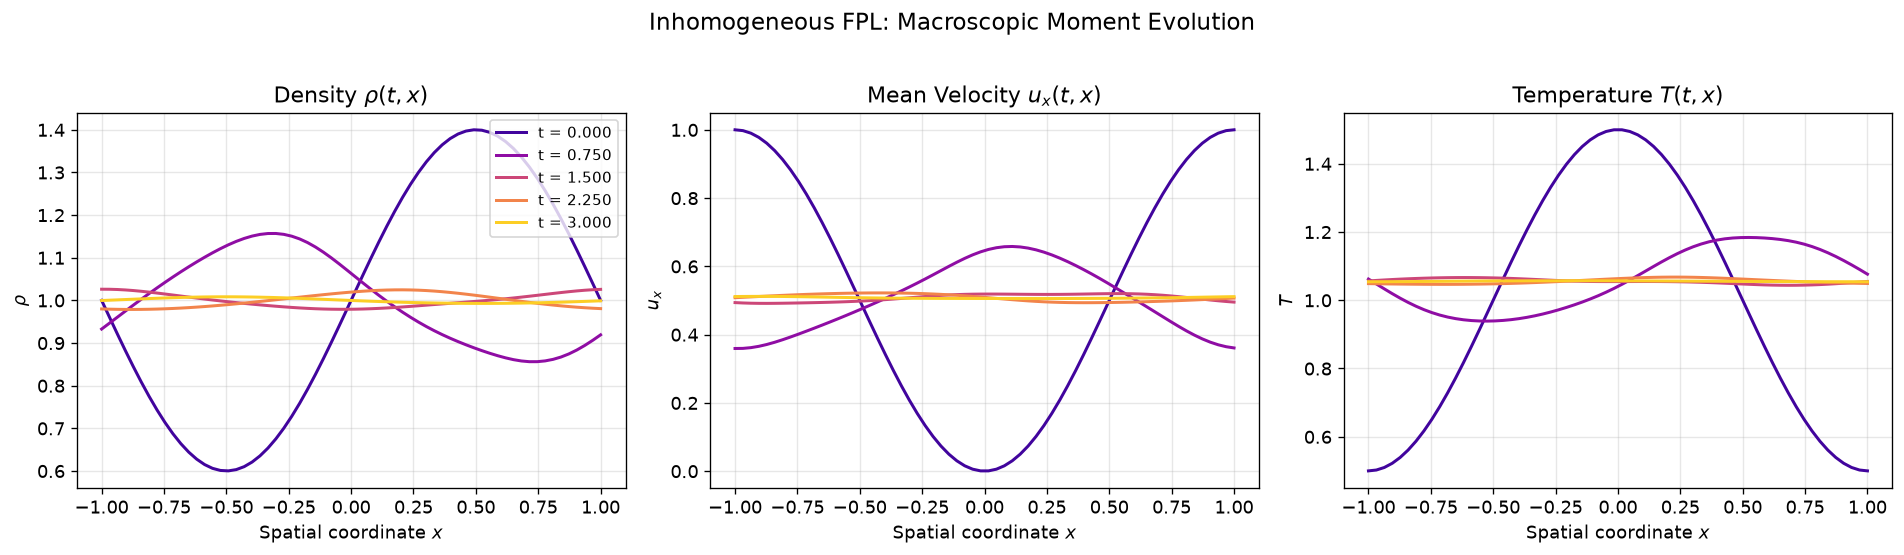

In [7]:
# Visualize spatial profile evolution of macroscopic moments
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

selected_indices = [0, num_times // 4, num_times // 2, 3 * num_times // 4, num_times - 1]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(selected_indices)))

for idx, color in zip(selected_indices, colors):
    t_val = time_array[idx]
    label = f"t = {t_val:.3f}"
    
    # Density profile
    axes[0].plot(x_coords.numpy(), rho_traj[idx].numpy(), label=label, color=color, lw=1.8)
    # Velocity profile
    axes[1].plot(x_coords.numpy(), u_x_traj[idx].numpy(), label=label, color=color, lw=1.8)
    # Temperature profile
    axes[2].plot(x_coords.numpy(), T_traj[idx].numpy(), label=label, color=color, lw=1.8)

axes[0].set_title(r"Density $\rho(t, x)$")
axes[0].set_xlabel("Spatial coordinate $x$")
axes[0].set_ylabel(r"$\rho$")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="upper right", fontsize=9)

axes[1].set_title(r"Mean Velocity $u_x(t, x)$")
axes[1].set_xlabel("Spatial coordinate $x$")
axes[1].set_ylabel(r"$u_x$")
axes[1].grid(True, alpha=0.3)

axes[2].set_title(r"Temperature $T(t, x)$")
axes[2].set_xlabel("Spatial coordinate $x$")
axes[2].set_ylabel(r"$T$")
axes[2].grid(True, alpha=0.3)

plt.suptitle("Inhomogeneous FPL: Macroscopic Moment Evolution", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()



### 4. Conservation Verification: Mass, Momentum, and Energy
We verify the exact conservation of total mass, momentum, and energy across the simulation.



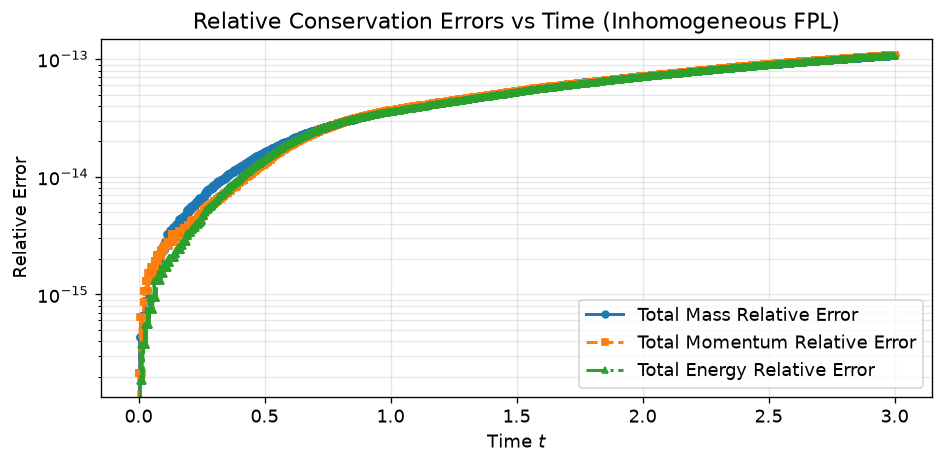

Max relative mass error:     1.09e-13
Max relative momentum error: 1.09e-13
Max relative energy error:   1.07e-13


In [8]:
# Total conserved quantities over time
v_sq_total = (v_x**2 + v_y**2).view(1, 1, N_v, N_v)

total_mass     = torch.sum(f_traj, dim=(1, 2, 3)) * (dv**2) * dx
total_momentum = torch.sum(f_traj * v_x.view(1, 1, N_v, N_v), dim=(1, 2, 3)) * (dv**2) * dx
total_energy   = 0.5 * torch.sum(f_traj * v_sq_total, dim=(1, 2, 3)) * (dv**2) * dx

rel_err_mass     = torch.abs(total_mass - total_mass[0]) / total_mass[0]
rel_err_momentum = torch.abs(total_momentum - total_momentum[0]) / (torch.abs(total_momentum[0]) + 1e-12)
rel_err_energy   = torch.abs(total_energy - total_energy[0]) / total_energy[0]

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(time_array, rel_err_mass.numpy(), 'o-', label="Total Mass Relative Error", lw=1.8, ms=4)
ax.semilogy(time_array, rel_err_momentum.numpy(), 's--', label="Total Momentum Relative Error", lw=1.8, ms=4)
ax.semilogy(time_array, rel_err_energy.numpy(), '^-.', label="Total Energy Relative Error", lw=1.8, ms=4)

ax.set_title("Relative Conservation Errors vs Time (Inhomogeneous FPL)")
ax.set_xlabel("Time $t$")
ax.set_ylabel("Relative Error")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Max relative mass error:     {rel_err_mass.max().item():.2e}")
print(f"Max relative momentum error: {rel_err_momentum.max().item():.2e}")
print(f"Max relative energy error:   {rel_err_energy.max().item():.2e}")



### 5. 3-Dimensional FPL Collision Term Demonstration
Following Section A.2 of **Pareschi, Russo, and Toscani (2000)**, we demonstrate the calculation of the 3-dimensional Fokker-Planck-Landau collision operator:
$$Q_L(f, f)(v) = \mathcal{F}^{-1} \left[ \hat{G}(k) - \hat{L}(k) \right]$$
using precomputed spherical and radial quadratures.



In [9]:
# Initialize 3D FPL Solver
solver_3d = FastSM_Landau_VHS(
    dimension           = 3,
    v_num_grid          = 8,
    v_max               = 4.0,
    vhs_coeff           = 1.0 / (4.0 * np.pi),  # 3D normalization
    vhs_alpha           = 0.0,
    quad_order_uniform  = 8,
    quad_order_legendre = 8,
)

# Create a 3D Maxwellian distribution
v3d = velocity_grid(3, 8, 4.0)  # shape: (8, 8, 8, 3)
v3d = v3d.view(1, 1, 1, 1, 8, 8, 8, 3)
v3d_sq = torch.sum(v3d**2, dim=-1, keepdim=True)
T_3d = 0.5
f_3d = (1.0 / (2.0 * np.pi * T_3d)**1.5) * torch.exp(-0.5 * v3d_sq / T_3d)

# Evaluate 3D collision operator in physical space
q_3d_phys = solver_3d.collision_operator_physical(f_3d)

print(f"3D Distribution function shape: {f_3d.shape}")
print(f"3D Collision term shape:        {q_3d_phys.shape}")
print(f"Max absolute collision value for Maxwellian: {torch.max(torch.abs(q_3d_phys)).item():.4e}")
print(f"Mean collision value (mass conservation):   {torch.mean(q_3d_phys).item():.4e}")



3D Distribution function shape: torch.Size([1, 1, 1, 1, 8, 8, 8, 1])
3D Collision term shape:        torch.Size([1, 1, 1, 1, 8, 8, 8, 1])
Max absolute collision value for Maxwellian: 5.9635e-02
Mean collision value (mass conservation):   1.8974e-19


End of file.
